# MSCM 684 1st Report

## Using Models examining Price in Airline Markets

### Gillen & Mantin (2009), Price Volatility in Airline Markets
Multiple Linear Regression Model explaining airfare volatility 

In [1]:
import pandas as pd
import numpy as np
import statsmodels.formula.api as smf
import matplotlib.pyplot as plt

# 1. Import and sort the dataset
df = pd.read_csv("airfare_30days_price.csv")
df = df.sort_values(["id", "time"]).copy()

df.head()

,id,time,origin,destination,distance,passengers,fare,carrier_lg,large_ms,fare_lg,carrier_low,lf_ms,fare_low
0,1,1,"ALBANY, NY","CHICAGO, IL",724,227.0,269.0,UA,43.08,277.0,AA,40.22,266.0
1,1,2,"ALBANY, NY","CHICAGO, IL",724,250.0,253.0,UA,42.34,273.0,AA,39.38,236.0
2,1,3,"ALBANY, NY","CHICAGO, IL",724,233.0,243.0,UA,46.04,252.0,AA,39.41,229.0
3,1,4,"ALBANY, NY","CHICAGO, IL",723,172.0,271.0,AA,46.41,257.0,AA,46.41,257.0
4,1,5,"ALBANY, NY","CHICAGO, IL",723,242.0,247.0,AA,45.39,232.0,AA,45.39,232.0


In [3]:
# 2. Calculate changes in average airfare
df["log_fare"] = np.log(df["fare"])

df["log_change"] = (
    df.groupby("id")["log_fare"].diff()
)

# 3. Calculate price volatility for each route
routes = df.groupby("id").agg(
    volatility=("log_change", "std"),
    distance=("distance", "mean"),
    passengers=("passengers", "mean"),
    largest_share=("large_ms", "mean"),
    lowest_fare_share=("lf_ms", "mean")
).dropna()

# 4. Transform variables
routes["distance_1000"] = routes["distance"] / 1000
routes["log_passengers"] = np.log1p(routes["passengers"])
routes["largest_share_10"] = routes["largest_share"] / 10
routes["lowest_fare_share_10"] = routes["lowest_fare_share"] / 10

In [4]:
# 5. Estimate multiple linear regression
model = smf.ols(
    "volatility ~ distance_1000 + log_passengers "
    "+ largest_share_10 + lowest_fare_share_10",
    data=routes
).fit(cov_type="HC3")

# 6. Display regression results
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:             volatility   R-squared:                       0.099
Model:                            OLS   Adj. R-squared:                  0.093
Method:                 Least Squares   F-statistic:                     18.88
Date:                Mon, 02 Nov 2026   Prob (F-statistic):           1.26e-14
Time:                        15:14:22   Log-Likelihood:                 1239.7
No. Observations:                 599   AIC:                            -2469.
Df Residuals:                     594   BIC:                            -2447.
Df Model:                           4                                         
Covariance Type:                  HC3                                         
                           coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------------
Intercept                0.0957 

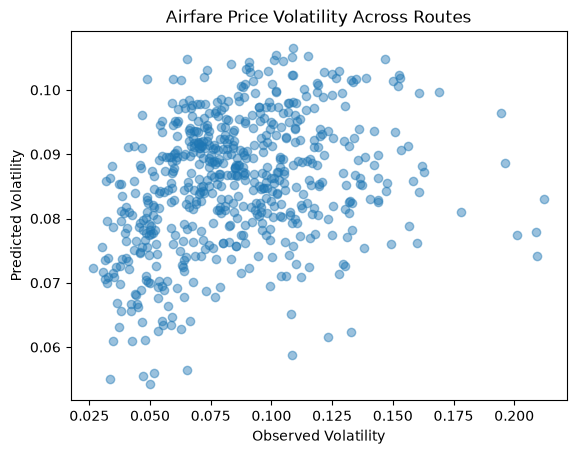

In [5]:
# 7. Compare observed and predicted volatility
routes["predicted_volatility"] = model.predict(routes)

plt.scatter(
    routes["volatility"],
    routes["predicted_volatility"],
    alpha=0.45
)

plt.xlabel("Observed Volatility")
plt.ylabel("Predicted Volatility")
plt.title("Airfare Price Volatility Across Routes")
plt.show()

### Mantin & Koo (2009) Dynamic Price Dispersion in Airline Markets
Multiple Linear Regression Model exploring how airfare price dispersion

In [6]:
# 1. Keep observations with valid positive fares
df_disp = df[df["fare"] > 0].copy()

In [7]:
# 2. Calculate price dispersion and route characteristics
routes_disp = df_disp.groupby("id").agg(
    avg_fare=("fare", "mean"),
    sd_fare=("fare", "std"),
    distance=("distance", "mean"),
    passengers=("passengers", "mean"),
    largest_share=("large_ms", "mean"),
    lowest_fare_share=("lf_ms", "mean")
)

# 3. Calculate coefficient of variation
routes_disp["dispersion_cv"] = (
    routes_disp["sd_fare"] / routes_disp["avg_fare"]
)

# 4. Transform variables
routes_disp["distance_1000"] = routes_disp["distance"] / 1000
routes_disp["log_passengers"] = np.log1p(routes_disp["passengers"])
routes_disp["largest_share_10"] = routes_disp["largest_share"] / 10
routes_disp["lowest_fare_share_10"] = routes_disp["lowest_fare_share"] / 10
routes_disp["avg_fare_100"] = routes_disp["avg_fare"] / 100

routes_disp = routes_disp.dropna()

In [8]:
# 5. Estimate multiple linear regression
dispersion_model = smf.ols(
    "dispersion_cv ~ distance_1000 + log_passengers "
    "+ largest_share_10 + lowest_fare_share_10 "
    "+ avg_fare_100",
    data=routes_disp
).fit(cov_type="HC3")

# 6. Display regression results
print(dispersion_model.summary())

                            OLS Regression Results                            
Dep. Variable:          dispersion_cv   R-squared:                       0.196
Model:                            OLS   Adj. R-squared:                  0.189
Method:                 Least Squares   F-statistic:                     26.66
Date:                Mon, 02 Nov 2026   Prob (F-statistic):           2.42e-24
Time:                        15:14:29   Log-Likelihood:                 935.69
No. Observations:                 599   AIC:                            -1859.
Df Residuals:                     593   BIC:                            -1833.
Df Model:                           5                                         
Covariance Type:                  HC3                                         
                           coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------------
Intercept               -0.0165 

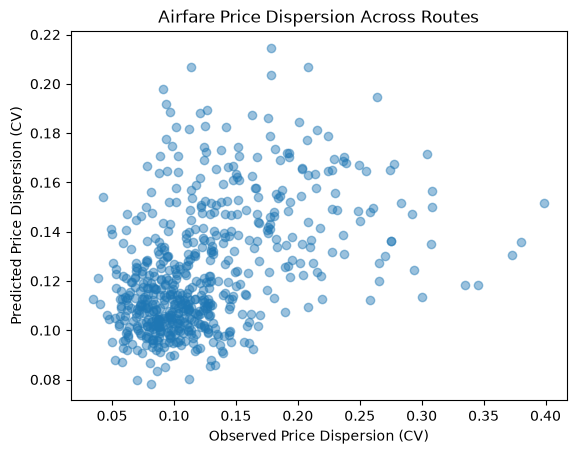

In [9]:
# 7. Compare observed and predicted dispersion
routes_disp["predicted_dispersion"] = dispersion_model.predict(routes_disp)

plt.scatter(
    routes_disp["dispersion_cv"],
    routes_disp["predicted_dispersion"],
    alpha=0.45
)

plt.xlabel("Observed Price Dispersion (CV)")
plt.ylabel("Predicted Price Dispersion (CV)")
plt.title("Airfare Price Dispersion Across Routes")
plt.show()

### Mantin & Koo (2010), Temporal Effects in Airfare Pricing
Comparing 2 Multiple Linear Regression Models to investigate whether airfares and price variation changes across observation periods

In [10]:
# 1. Prepare the dataset
df_time = df.sort_values(["id", "time"]).copy()

df_time["time_sq"] = df_time["time"] ** 2

In [11]:
# 2. Calculate airfare variation
df_time["route_mean_fare"] = (
    df_time.groupby("id")["fare"].transform("mean")
)

df_time["abs_deviation"] = (
    df_time["fare"] - df_time["route_mean_fare"]
).abs()

In [ ]:
# 3. Estimate average airfare regression
price_model = smf.ols(
    "fare ~ time + time_sq + C(id)",
    data=df_time
).fit(
    cov_type="cluster",
    cov_kwds={"groups": df_time["id"]}
)

# 4. Estimate airfare variation regression
variation_model = smf.ols(
    "abs_deviation ~ time + time_sq + C(id)",
    data=df_time
).fit(
    cov_type="cluster",
    cov_kwds={"groups": df_time["id"]}
)

In [ ]:
# 5. Display main regression results
for name, model in [
    ("Average Fare", price_model),
    ("Airfare Variation", variation_model)
]:
    print("\n", name)

    print(pd.DataFrame({
        "Coefficient": model.params[["time", "time_sq"]],
        "P-value": model.pvalues[["time", "time_sq"]]
    }))

    print("R-squared:", round(model.rsquared, 3))
    print(
        "Joint time effect p-value:",
        float(model.f_test("time = 0, time_sq = 0").pvalue)
    )

In [ ]:
# 6. Visualize average airfare across periods
period_means = df_time.groupby("time")[
    ["fare", "abs_deviation"]
].mean()

period_means["fare"].plot(marker="o")

plt.xlabel("Observation Period")
plt.ylabel("Average Fare Paid")
plt.title("Average Airfare Across Observation Periods")
plt.show()

# 7. Visualize airfare variation across periods
period_means["abs_deviation"].plot(marker="o")

plt.xlabel("Observation Period")
plt.ylabel("Average Absolute Fare Deviation")
plt.title("Airfare Variation Across Observation Periods")
plt.show()

In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from functools import partial
from fpppy.utils import plot_series
from statsmodels.graphics.tsaplots import plot_acf
from statsforecast import StatsForecast
from statsforecast.models import Naive, SeasonalNaive, AutoETS
from utilsforecast.evaluation import evaluate
from utilsforecast.losses import rmse, mae, mape, mase

plt.rcParams["figure.constrained_layout.use"] = True

In [2]:
air = pd.read_csv("airfare_30days_price.csv")

avg = (
    air.groupby("time", as_index=False)
    .agg({"fare": "mean"})
    .rename(columns={"time": "ds", "fare": "y"})
    .assign(unique_id="All routes")
)
avg = avg.assign(
    Quarter=(avg["ds"] - 1) % 4 + 1,
    Year=(avg["ds"] - 1) // 4 + 1,
)
avg.head()

,ds,y,unique_id,Quarter,Year
0,1,161.060100,All routes,1,1
1,2,158.133556,All routes,2,1
2,3,164.532554,All routes,3,1
3,4,173.430718,All routes,4,1
4,5,166.762938,All routes,1,2


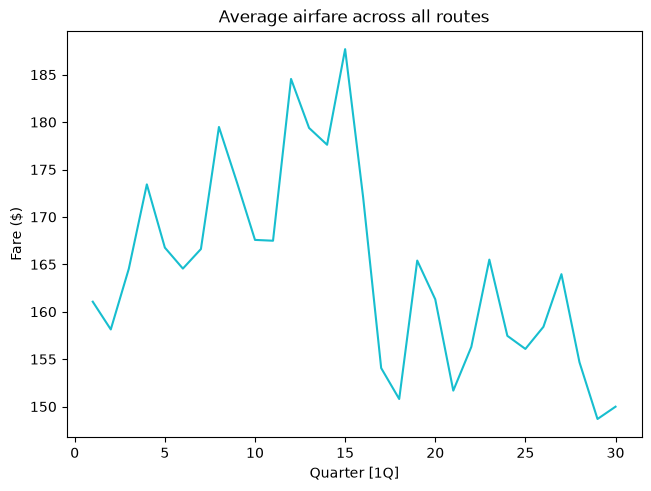

In [3]:
#https://otexts.com/fpppy/02-graphics.html#time-plots
plot_series(avg,
    xlabel="Quarter [1Q]", ylabel="Fare ($)",
    title="Average airfare across all routes")

C:\Users\canad\AppData\Local\Temp\ipykernel_8972\4108246942.py:22: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


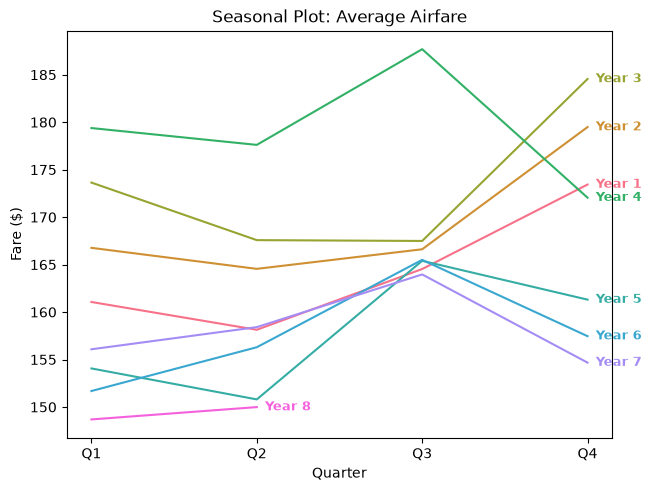

In [4]:
# https://otexts.com/fpppy/02-graphics.html#seasonal-plots
unique_years = avg["Year"].unique()
year_palette = sns.color_palette("husl", n_colors=len(unique_years))
fig, ax = plt.subplots()
sns.lineplot(data=avg, x="Quarter", y="y",
  hue="Year", palette=year_palette, legend=False, ax=ax)

ax.set(
    title="Seasonal Plot: Average Airfare",
    xlabel="Quarter",
    ylabel="Fare ($)",
    xticks=range(1, 5),
    xticklabels=["Q1", "Q2", "Q3", "Q4"],
)
min_year = unique_years.min()
for year, subset in avg.groupby("Year"):
    x = subset["Quarter"].iloc[-1] + .05
    y = subset["y"].iloc[-1]
    color = year_palette[year - min_year]
    ax.text(x, y, "Year " + str(year),
        ha="left", va="center", fontsize=9, weight="bold", color=color)
fig.show()

C:\Users\canad\AppData\Local\Temp\ipykernel_8972\1001908310.py:12: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


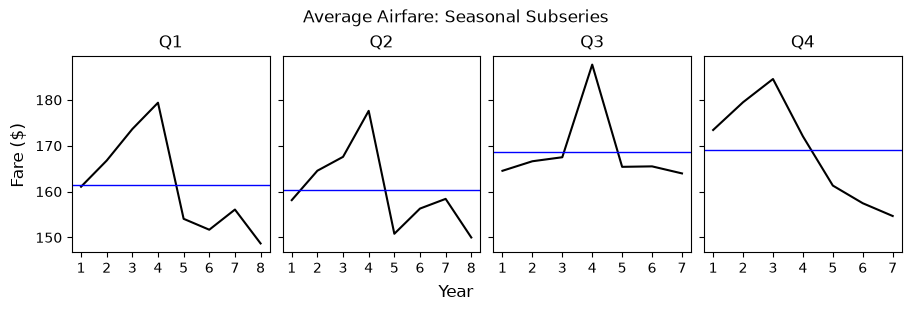

In [5]:
# https://otexts.com/fpppy/02-graphics.html#seasonal-subseries-plots
fig, axes = plt.subplots(1, 4, figsize=(9, 3), sharey=True)
for ax, (quarter, q_df) in zip(axes, avg.groupby("Quarter")):
    mean_fare = q_df["y"].mean()
    ax.plot(q_df["Year"], q_df["y"], color="k")
    ax.axhline(mean_fare, color="b", linewidth=1)
    ax.set(title="Q" + str(quarter), xlabel="", xticks=q_df["Year"])

fig.suptitle("Average Airfare: Seasonal Subseries")
fig.supxlabel("Year")
fig.supylabel("Fare ($)")
fig.show()

C:\Users\canad\AppData\Local\Temp\ipykernel_8972\4113040704.py:9: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


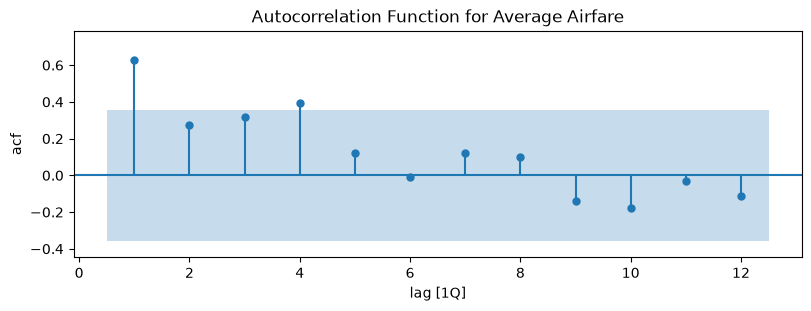

In [6]:
# https://otexts.com/fpppy/02-graphics.html#autocorrelation
fig, ax = plt.subplots(figsize=(8, 3))
plot_acf(avg["y"], lags=12, ax=ax,
    zero=False, bartlett_confint=False, auto_ylims=True)
ax.set(
    title="Autocorrelation Function for Average Airfare",
    xlabel="lag [1Q]", ylabel="acf",
)
fig.show()

In [7]:
# https://otexts.com/fpppy/05-toolbox.html
train = avg.loc[avg["ds"] <= 22, ["unique_id", "ds", "y"]]
test = avg.loc[avg["ds"] > 22]

naive_method = Naive()
seasonal_naive_method = SeasonalNaive(4)
ets_method = AutoETS(season_length=4)
sf = StatsForecast(
    models=[naive_method, seasonal_naive_method, ets_method],
    freq=1,
)
sf.fit(train)
fcasts = sf.predict(h=8).assign(y=test["y"].to_numpy())

evaluation = evaluate(fcasts, train_df=train,
    metrics=[rmse, mae, mape, partial(mase, seasonality=4)])
evaluation

,unique_id,metric,Naive,SeasonalNaive,AutoETS
0,All routes,rmse,5.586076,4.084036,5.625563
1,All routes,mae,4.487437,3.479023,4.511953
2,All routes,mape,0.028523,0.022551,0.028623
3,All routes,mase,0.454754,0.352562,0.457239


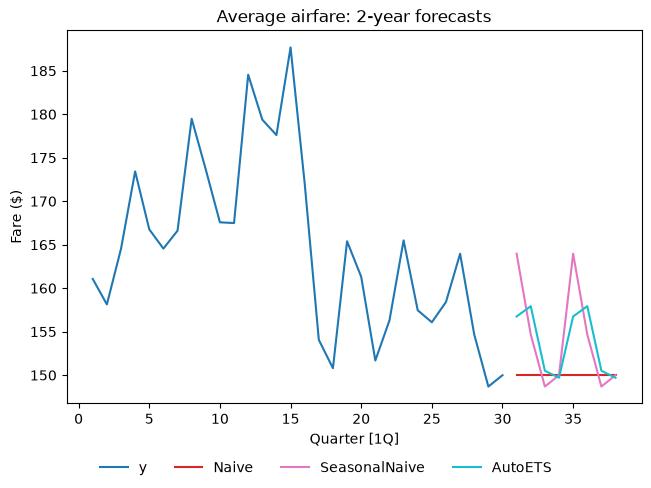

In [8]:
fc = sf.forecast(df=avg[["unique_id", "ds", "y"]], h=8)
plot_series(avg, fc,
    xlabel="Quarter [1Q]", ylabel="Fare ($)",
    title="Average airfare: 2-year forecasts",
    rm_legend=False,
    legend_loc="outside lower center")